In [3]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
folder_path = "C:/Users/nagal/OneDrive/Documents/Learn/Repo/Olist-Project/data"
data = {}
for file in os.listdir(folder_path):
    # print(file.split(".")[0])
    data[file.split(".")[0].replace("olist_","").replace("_dataset","").replace("order_","")] = folder_path + "/" + file
data

{'customers': 'C:/Users/nagal/OneDrive/Documents/Learn/Repo/Olist-Project/data/olist_customers_dataset.csv',
 'geolocation': 'C:/Users/nagal/OneDrive/Documents/Learn/Repo/Olist-Project/data/olist_geolocation_dataset.csv',
 'orders': 'C:/Users/nagal/OneDrive/Documents/Learn/Repo/Olist-Project/data/olist_orders_dataset.csv',
 'items': 'C:/Users/nagal/OneDrive/Documents/Learn/Repo/Olist-Project/data/olist_order_items_dataset.csv',
 'payments': 'C:/Users/nagal/OneDrive/Documents/Learn/Repo/Olist-Project/data/olist_order_payments_dataset.csv',
 'reviews': 'C:/Users/nagal/OneDrive/Documents/Learn/Repo/Olist-Project/data/olist_order_reviews_dataset.csv',
 'products': 'C:/Users/nagal/OneDrive/Documents/Learn/Repo/Olist-Project/data/olist_products_dataset.csv',
 'sellers': 'C:/Users/nagal/OneDrive/Documents/Learn/Repo/Olist-Project/data/olist_sellers_dataset.csv',
 'product_category_name_translation': 'C:/Users/nagal/OneDrive/Documents/Learn/Repo/Olist-Project/data/product_category_name_transla

In [ ]:
purchase → approval
purchase → shipping
purchase → delivery
estimated delivery → actual delivery
Questions:

70. What is the average delivery time?

71. What percentage of orders are delivered late?

72. Which categories have longer delivery times?

73. Which states have longer delivery times?

74. Do late deliveries have lower review scores?-------------------------------> clarity

75. What is the relationship between delivery time and review score?



In [ ]:
70. What is the average delivery time?
I calculated the difference between the delivery date and purchase date for each order.
Then I converted the time difference from seconds to days and calculated the mean to get the average delivery time.
    dt.total_seconds() ----> converts the duration to seconds.
    average delivery time: 12.56


In [4]:
df_orders = pd.read_csv(data["orders"])
df_orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [5]:
df_orders["order_purchase_timestamp"] = pd.to_datetime(df_orders["order_purchase_timestamp"])
df_orders["order_approved_at"] = pd.to_datetime(df_orders["order_approved_at"])
df_orders["order_delivered_carrier_date"] = pd.to_datetime(df_orders["order_delivered_carrier_date"])
df_orders["order_delivered_customer_date"] = pd.to_datetime(df_orders["order_delivered_customer_date"])
df_orders["order_estimated_delivery_date"] = pd.to_datetime(df_orders["order_estimated_delivery_date"])


In [6]:
df_orders.dtypes

order_id                                 object
customer_id                              object
order_status                             object
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object

In [7]:
date_difference = df_orders["order_delivered_customer_date"] - df_orders["order_purchase_timestamp"] 
delivery_days = date_difference.dt.total_seconds() / (24 * 60 * 60)
average_delivery_time = (delivery_days).mean().round(2)
print("average delivery time:",average_delivery_time)

average delivery time: 12.56


In [ ]:
71. What percentage of orders are delivered late?
I compared the actual delivery date with the estimated delivery date. 
If the actual delivery date was later than the estimated date, I considered the order late. 
Then I divided the number of late orders by the total number of delivered orders and multiplied by 100 to calculate the percentage.”
        Percentage of orders delivered late: 8.112898544715783


In [8]:
late_deliveries = (df_orders["order_delivered_customer_date"]>df_orders["order_estimated_delivery_date"]).value_counts()
total_no_orders = df_orders["order_delivered_customer_date"].count()
late_percentage = (late_deliveries[True] / total_no_orders) * 100
print("Percentage of orders delivered late:", late_percentage)


Percentage of orders delivered late: 8.112898544715783


In [9]:
(late_deliveries/total_no_orders)*100

False    94.960405
True      8.112899
Name: count, dtype: float64

In [ ]:
72. Which categories have longer delivery times?
I calculated minimum, maximum, average, and count of delivery time for each product category. 
Based on average delivery time, office furniture (moveis_escritorio) has the longest delivery time at 
approximately 20.84 days. I would also consider the number of orders because categories 
with very few orders may not provide reliable results. 
The very high maximum delivery time also suggests there may be outliers that need further investigation."

In [10]:
df_products = pd.read_csv(data["products"])
df_products.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [11]:
df_items = pd.read_csv(data["items"])
df_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [12]:
products_items = pd.merge(df_products,df_items,on="product_id",how="inner")
products_items_orders_st = pd.merge(products_items,df_orders,on="order_id",how="inner")
products_items_orders = products_items_orders_st.dropna(subset=["order_delivered_customer_date"]).copy()
products_items_orders["delivery_time_days"] = (products_items_orders["order_delivered_customer_date"] - products_items_orders["order_purchase_timestamp"]).dt.total_seconds() /(24*60*60)
category_delivery  = (products_items_orders.groupby("product_category_name")["delivery_time_days"].agg(["min","max","mean","count"]).sort_values("mean",ascending=False))
pd.set_option("display.expand_frame_repr", False)
print(category_delivery )

                                                     min         max       mean  count
product_category_name                                                                 
moveis_escritorio                               1.029954  194.850174  20.841449   1668
artigos_de_natal                                2.758426   88.241725  15.740684    150
fashion_calcados                                3.146424   53.112905  15.441354    257
seguros_e_servicos                             11.057546   19.218762  15.138154      2
casa_conforto_2                                 3.209815   44.146597  14.573525     30
...                                                  ...         ...        ...    ...
fashion_roupa_infanto_juvenil                   1.970185   29.738067   8.819476      7
portateis_cozinha_e_preparadores_de_alimentos   3.183935   19.136389   8.145604     14
livros_importados                               1.081505   26.529271   8.126521     57
la_cuisine                                 

In [13]:
products_items_orders_st.shape

(112650, 22)

In [14]:
products_items_orders.shape

(110196, 23)

In [ ]:
73. Which states have longer delivery times?
I merged the orders and customers datasets using `customer_id` and calculated delivery time as the difference between 
the purchase date and the actual delivery date. Then I grouped the data by customer state and calculated the average delivery time.

Based on my analysis, RR has the longest average delivery time at approximately 29.39 days, 
followed by AP at 27.19 days and AM at 26.43 days. 
This suggests that these states may require further investigation to improve delivery efficiency.


In [15]:
df_customers = pd.read_csv(data["customers"])
df_customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [16]:
df_orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


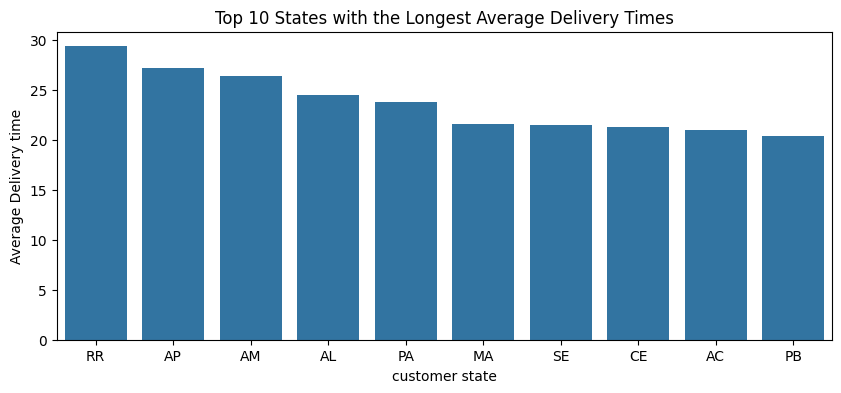

In [17]:
df_orders["time_diff"] = (df_orders["order_delivered_customer_date"] - df_orders["order_purchase_timestamp"]).dt.total_seconds()/(24*60*60)
orders_customers = pd.merge(df_orders,df_customers,on="customer_id",how="inner")
orders_customers_delay = (orders_customers.dropna(subset=["order_delivered_customer_date"])
    .groupby("customer_state")["time_diff"].mean().sort_values(ascending=False).reset_index(name="avg_delivery_days").head(10))
plt.figure(figsize=(10,4))
plt.title("Top 10 States with the Longest Average Delivery Times")
sns.barplot(data=orders_customers_delay,x="customer_state",y="avg_delivery_days")    
plt.xlabel("customer state")
plt.ylabel("Average Delivery time")
plt.show()

In [18]:
orders_customers

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,time_diff,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,8.436574,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,13.782037,af07308b275d755c9edb36a90c618231,47813,barreiras,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,9.394213,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,13.208750,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2.873877,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP
...,...,...,...,...,...,...,...,...,...,...,...,...,...
99436,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28,8.218009,6359f309b166b0196dbf7ad2ac62bb5a,12209,sao jose dos campos,SP
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02,22.193727,da62f9e57a76d978d02ab5362c509660,11722,praia grande,SP
99438,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27,24.859421,737520a9aad80b3fbbdad19b66b37b30,45920,nova vicosa,BA
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15,17.086424,5097a5312c8b157bb7be58ae360ef43c,28685,japuiba,RJ


In [ ]:
74. Do late deliveries have lower review scores?
I analyzed whether late deliveries affect customer review scores by calculating delivery delays and 
comparing the average review scores of late and on-time orders.

The average review score for on-time deliveries was 4.21, whereas late deliveries had an average score of 2.57. 
    The correlation between delivery delay and review score was approximately -0.27, indicating a weak negative relationship.

Based on these results, late deliveries are associated with lower customer review scores. 
    The business should investigate delivery delays and improve delivery performance to help increase customer satisfaction.


   late_delivery  review_score
0          False      4.214307
1           True      2.566550
the correlation between deliveries and reviews: -0.26641402617274795


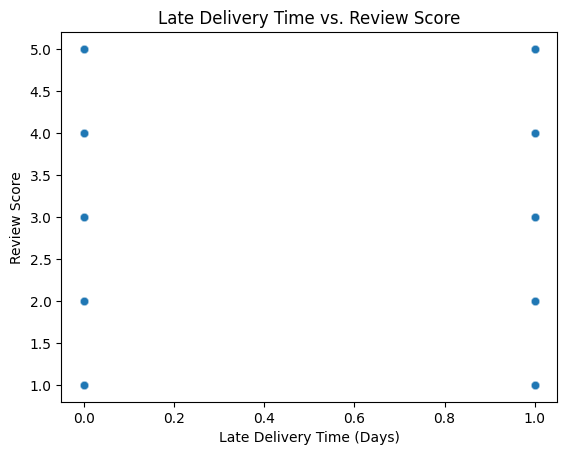

In [19]:
df_orders["delay"] = (df_orders["order_delivered_customer_date"] - df_orders["order_estimated_delivery_date"]).dt.total_seconds()/(24*60*60)
df_reviews = pd.read_csv(data["reviews"])
df_reviews = df_reviews.dropna(subset=["review_score"])
orders_reviews = pd.merge(df_orders,df_reviews,on="order_id",how="inner")
orders_reviews["late_delivery"] = (
    orders_reviews["delay"] > 0
)
review_comparison = (
    orders_reviews.groupby("late_delivery")["review_score"]
    .mean()
    .reset_index()
)

print(review_comparison)

print("the correlation between deliveries and reviews:",orders_reviews["delay"].corr(orders_reviews["review_score"]))
sns.scatterplot(
    data=orders_reviews,
    x="late_delivery",
    y="review_score",
    alpha=0.3
)

plt.title("Late Delivery Time vs. Review Score")
plt.xlabel("Late Delivery Time (Days)")
plt.ylabel("Review Score")
plt.show()

   late_delivery      mean  count
0          False  4.293578  88658
1           True  2.566550   7701


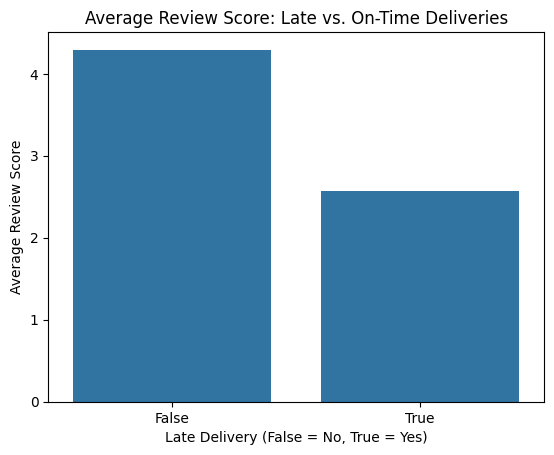

In [215]:

df_orders["delay"] = (
    df_orders["order_delivered_customer_date"]
    - df_orders["order_estimated_delivery_date"]
).dt.total_seconds() / (24 * 60 * 60)

df_reviews = pd.read_csv(data["reviews"])
df_reviews = df_reviews.dropna(subset=["review_score"])

orders_reviews = pd.merge(
    df_orders,
    df_reviews,
    on="order_id",
    how="inner"
)

# Remove rows without the dates or scores needed for analysis
orders_reviews = orders_reviews.dropna(
    subset=["delay", "review_score"]
).copy()

orders_reviews["late_delivery"] = orders_reviews["delay"] > 0

review_comparison = (
    orders_reviews.groupby("late_delivery")["review_score"]
    .agg(["mean", "count"])
    .reset_index()
)

print(review_comparison)

sns.barplot(
    data=orders_reviews,
    x="late_delivery",
    y="review_score",
    errorbar=None
)

plt.title("Average Review Score: Late vs. On-Time Deliveries")
plt.xlabel("Late Delivery (False = No, True = Yes)")
plt.ylabel("Average Review Score")
plt.show()

In [162]:
df_reviews["review_score"].isna().value_counts()

review_score
False    99224
Name: count, dtype: int64

In [184]:
orders_reviews["delay"].value_counts().sort_values(ascending=False)

delay
12.385602    5
13.144051    5
7.195324     4
15.084213    4
13.283183    4
            ..
28.274595    1
13.340590    1
25.490127    1
11.914456    1
17.452431    1
Name: count, Length: 91313, dtype: int64

In [192]:
(orders_reviews["delay"] >= 20).value_counts().max()

85730

In [203]:
orders_reviews["delay"].sort_values(ascending=False)

55478    188.975081
11398    175.869109
81231    167.708414
88947    166.583380
61461    165.633912
            ...    
99066           NaN
99096           NaN
99130           NaN
99131           NaN
99198           NaN
Name: delay, Length: 99224, dtype: float64

In [ ]:
def transform_time(point):
    if point < 1:
        point = "delay_time_1day"
    elif point >=1 and point <= 3:
        point = "delay_time_3days"
    elif point >3 and point <= 5:
        point = "delay_time_5days"
    else:
        point = "approval_over_5h"
    return point

In [ ]:
75. What is the relationship between delivery time and review score?
I calculated the Pearson correlation between delivery time and customer review scores. 
The correlation was approximately -0.334, indicating a moderate negative relationship. 
This suggests that longer delivery times tend to be associated with lower customer review scores.
 correlation does not actually the reason  may be other factors  also influence customer satisfaction.

In [205]:
df_orders.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'delay'],
      dtype='object')

In [206]:
df_reviews.columns

Index(['review_id', 'order_id', 'review_score', 'review_comment_title',
       'review_comment_message', 'review_creation_date',
       'review_answer_timestamp'],
      dtype='object')

Correlation between delivery time and review score: -0.3338040907668422


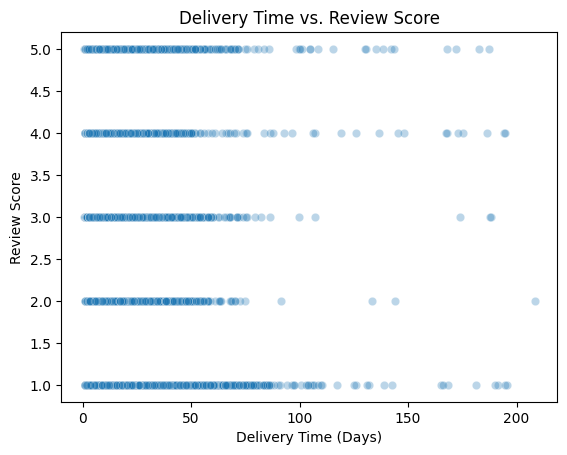

In [212]:
df_orders["delivery_time_days"] = (df_orders["order_delivered_customer_date"] - df_orders["order_purchase_timestamp"]).dt.total_seconds() / (24 * 60 * 60)
df_reviews = pd.read_csv(data["reviews"])
df_reviews = df_reviews.dropna(subset=["review_score"])
orders_reviews = pd.merge(
    df_orders,
    df_reviews,
    on="order_id",
    how="inner"
)
orders_reviews = orders_reviews.dropna(
    subset=["delivery_time_days", "review_score"]
)

correlation = orders_reviews["delivery_time_days"].corr(
    orders_reviews["review_score"]
)

print("Correlation between delivery time and review score:", correlation)
sns.scatterplot(
    data=orders_reviews,
    x="delivery_time_days",
    y="review_score",
    alpha=0.3
)

plt.title("Delivery Time vs. Review Score")
plt.xlabel("Delivery Time (Days)")
plt.ylabel("Review Score")
plt.show()